In [1]:
# conda env 'vis2'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')
import visualization as vis

import warnings
warnings.filterwarnings("ignore")


In [2]:
at3d_obs_file = '../../../../../intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
iter_dir = '../iterations/'

In [3]:
out_dir = './brf_diff_movie/'
vis.brf_diff_frames(at3d_obs_file, iter_dir, out_dir, 'MISR', s=2, brf_vmin=0, brf_vmax=0.5, diff_range=0.25)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

Movie saved at ./brf_diff_movie/movie.gif


In [4]:
out_dir = './optical_depth_movie/'
vis.optical_depth_frames(iter_dir, out_dir, vmin=0.1, vmax=20, log=True)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

Movie saved at ./optical_depth_movie/movie.gif


In [5]:
x = 3.3
x_str = '{:.2f}'.format(x).replace('.','p')
out_dir = './extinction_cs_x_{}_log_movie/'.format(x_str)
vis.extinction_cross_section_frames(iter_dir, out_dir, dim='x', loc=x, vmin=0.1, vmax=25, log=True)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

Movie saved at ./extinction_cs_x_3p30_log_movie/movie.gif


In [3]:
### 1D Tau
from util import load_sensor_dict
import numpy as np
import glob
import at3d
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

# 1D tau vs AT3D tau
tau1D_file = '../../../../../intermediate_data/AT3D_1DTAU_CAMP2Ex_RF17_default_1400.nc'
# obs_file = '../../../../intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'

iter_files = np.sort(glob.glob(iter_dir + 'iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])

cloud_3D = solvers[0.67].medium['cloud']

obs = load_sensor_dict(tau1D_file)
cloud_1D = obs['MISR']['sensor_list'][4]

x_1D = cloud_1D.ray_x.data
y_1D = cloud_1D.ray_y.data
tau_1D = cloud_1D.tau.data

x_3D = cloud_3D.x.data
y_3D = cloud_3D.y.data

grid_x, grid_y = np.meshgrid(x_3D, y_3D, indexing='ij')
tau_1D_interpolated = griddata((x_1D, y_1D), tau_1D, (grid_x, grid_y), method='linear')
I_interp = griddata((x_1D, y_1D), cloud_1D.I.data*np.pi/cloud_1D.mu0.data, (grid_x, grid_y), method='linear')

cloud_3D['tau_3D'] = cloud_3D.extinction.integrate('z')
cloud_3D['tau_1D_interp'] = (['x', 'y'], tau_1D_interpolated)
cloud_3D['I'] = (['x', 'y'], I_interp)


Text(0.5, 1.0, 'Difference\nAT3D - 1D')

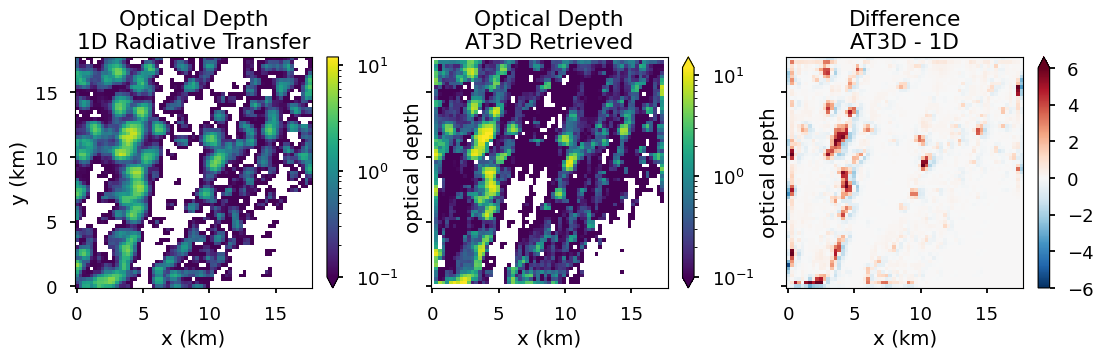

In [4]:

import matplotlib.colors as colors
vmin = 0
vmax = 12
vrange = 6
plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 3, figsize=(13,3), sharex=True, sharey=True)
# cloud_3D.tau_1D_interp.plot(ax=ax[0], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
# cloud_3D.tau_3D.plot(ax=ax[1], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
cloud_3D.tau_1D_interp.plot(ax=ax[0], y='y', cbar_kwargs={'label': 'optical depth'}, norm=colors.LogNorm(vmin=0.1, vmax=vmax))
cloud_3D.tau_3D.plot(ax=ax[1], y='y', cbar_kwargs={'label': 'optical depth'}, norm=colors.LogNorm(vmin=0.1, vmax=vmax))
(cloud_3D.tau_3D - cloud_3D.tau_1D_interp).plot(ax=ax[2], y='y', vmin=-vrange, vmax=vrange, cmap='RdBu_r')
ax[0].set_ylabel('y (km)')
ax[0].set_xlabel('x (km)')
ax[0].set_title('Optical Depth\n1D Radiative Transfer')
ax[1].set_ylabel('')
ax[1].set_xlabel('x (km)')
ax[1].set_title('Optical Depth\nAT3D Retrieved')
ax[2].set_ylabel('')
ax[2].set_xlabel('x (km)')
ax[2].set_title('Difference\nAT3D - 1D')


0.20039718875372703


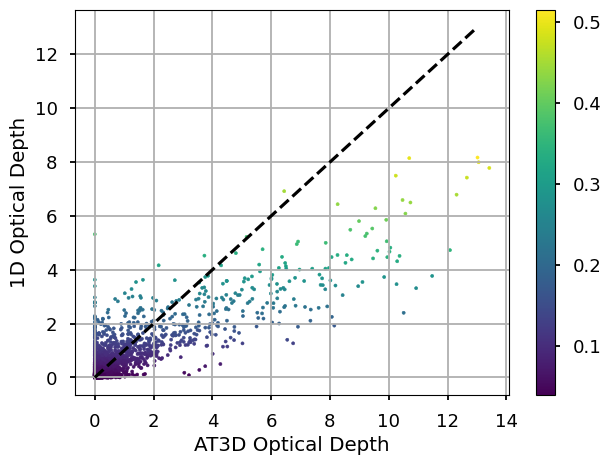

In [5]:

# cond = cloud_3D.tau_3D.data > 0
cond = cloud_3D.I.data > 0.040
plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 1, figsize=(7,5))
s = ax.scatter(cloud_3D.tau_3D.data[cond], cloud_3D.tau_1D_interp.data[cond], c=cloud_3D.I.data[cond], s=5)
plt.colorbar(s)
ax.plot([0,13], [0,13], 'k', linestyle='--')
ax.set_xlabel('AT3D Optical Depth')
ax.set_ylabel('1D Optical Depth')
ax.grid()

mean_tau1d = np.mean(cloud_3D.tau_1D_interp.data[cond])
mean_tau3d = np.mean(cloud_3D.tau_3D.data[cond])
print((mean_tau3d - mean_tau1d) / mean_tau3d)


In [7]:
def rmse(x_r, x_t):
    return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5

def bias(x_r, x_t):
    return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))

Text(0.5, 1.0, '1D vs 3D optical depth\nCloud Volume Constrained')

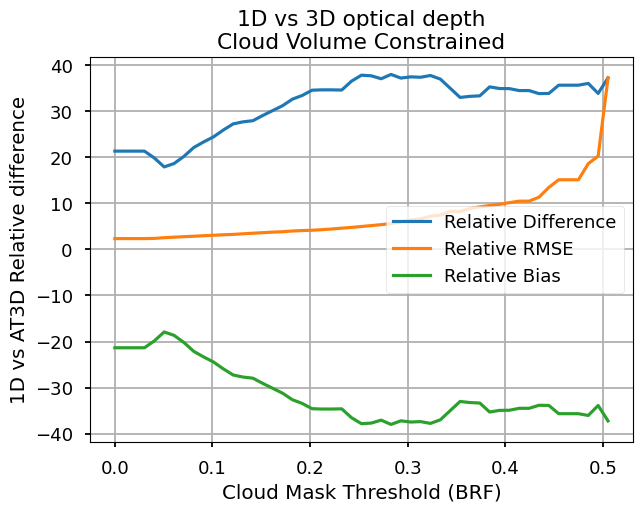

In [10]:
ths = np.linspace(0, 1.0, 100)
rel_diff = np.zeros(ths.shape)
rel_rmse = np.zeros(ths.shape)
rel_bias = np.zeros(ths.shape)
for i, th in enumerate(ths):
    # cond = cloud_3D.tau_3D.data > th
    cond = cloud_3D.I.data > th
    tau1d = cloud_3D.tau_1D_interp.data[cond]
    tau3d = cloud_3D.tau_3D.data[cond]
    mean_tau1d = np.mean(tau1d)
    mean_tau3d = np.mean(tau3d)
    rel_diff[i] = 100 * (mean_tau3d - mean_tau1d) / mean_tau3d
    rel_rmse[i] = rmse(tau1d, tau3d)
    rel_bias[i] = bias(tau1d, tau3d)
f, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.plot(ths, rel_diff, label='Relative Difference')
ax.plot(ths, rel_rmse, label='Relative RMSE')
ax.plot(ths, rel_bias, label='Relative Bias')
ax.set_xlabel('Cloud Mask Threshold (BRF)')
ax.set_ylabel('1D vs AT3D Relative difference')
ax.grid()
ax.legend()
# ax.set_ylim([0, 0.33])
ax.set_title('1D vs 3D optical depth\nCloud Volume Constrained')
# ax.vlines(0.04, 0, 0.6, 'k')